# Imports

In [1]:
from utils import *
import pandas as pd
import numpy as np
from scipy.stats import norm, gaussian_kde
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from matplotlib.lines import Line2D
from matplotlib.patches import Patch


# Setup

In [2]:
##############################
# Read Dataset into Dataframe
##############################

# path to cleaned dataset
clean_path = r'../data/mnz_cleaned.csv'


##### read into df...
df = pd.read_csv(clean_path)
df.sort_values('error', inplace=True)
df.reset_index(inplace=True)


df.head()

,level_0,index,sample,zone,mnz,texture,texture_chem,n,age,error,...,Er2O3,Tm2O3,Yb2O3,SO3,PbO,percent,lree,HREE,garnet,cordierite
0,0,8,EB14-001,CMZI,m28,overgrowth,Y depleted overgrowth,6.0,348.85,0.683097,...,0.034439,0.069372,0.009740,0.018835,0.096939,0.195814,59.804756,1.359903,1,0
1,2,176,P14-005A-5B,CBSZ,m20,core,Y depleted core,NaN,356.00,0.784962,...,0.014718,0.009812,0.009812,0.020605,0.079477,0.220495,61.972776,1.588568,1,0
2,1,111,P14-003-2B,MDHSZ,m50,core,Th enriched core,5.0,307.14,0.789124,...,0.009937,0.019969,0.009937,0.018184,0.132687,0.256926,57.520514,0.670830,1,0
3,3,114,M1605-2-L3,MDHSZ,m4,rim,Y depleted rim,5.0,298.70,1.346540,...,0.009748,0.009748,0.009748,0.016339,0.082968,0.450800,61.526147,1.376610,1,0
4,4,31,WA14-002,CMZI,m22,rim,Y depleted rim,5.0,353.24,1.408622,...,0.009641,0.060215,0.009641,0.014777,0.085454,0.398772,60.699177,1.389823,1,1


# K-Means

## Determine Number of Clusters

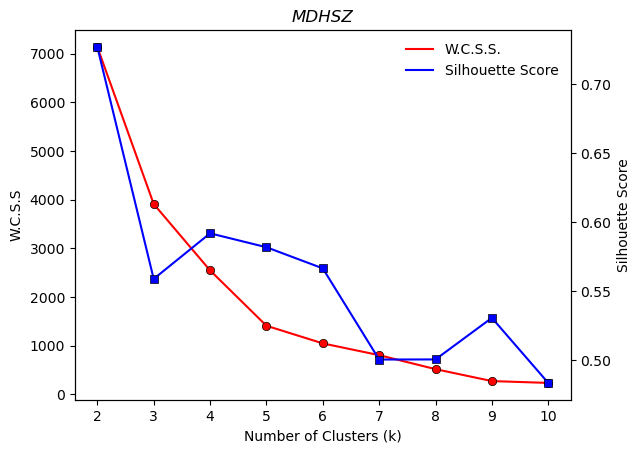

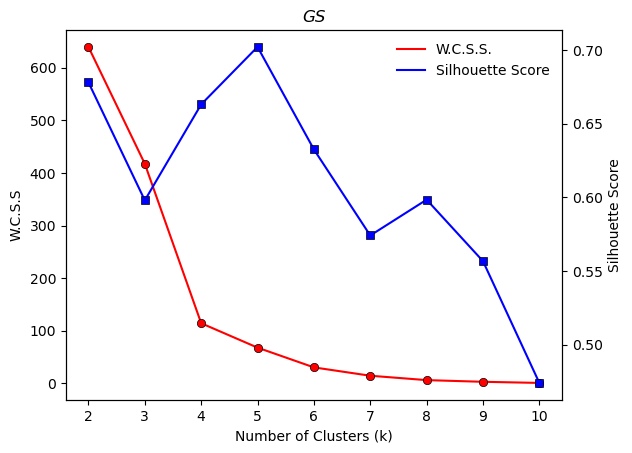

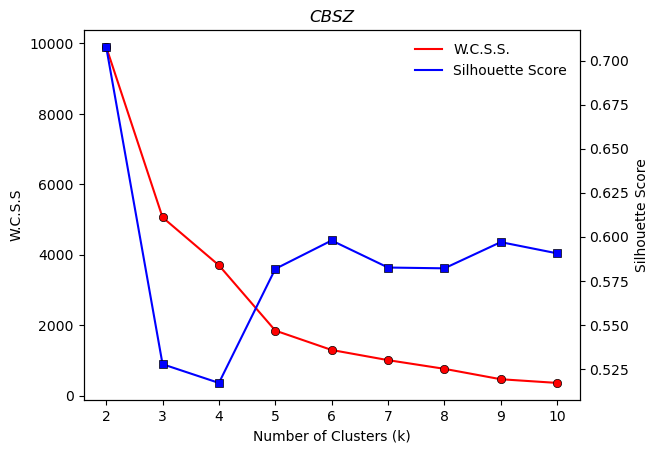

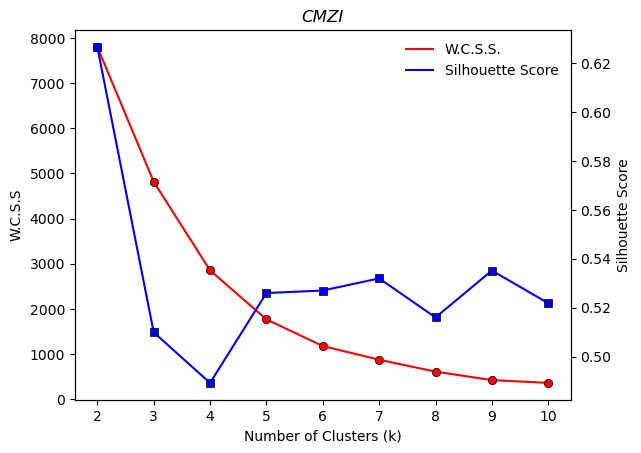

In [5]:


for zone in ['MDHSZ', 'GS', 'CBSZ', 'CMZI']:

    df_subset = df[df['zone']==zone]

    ages = df_subset['age'].to_numpy().reshape(-1,1)
    errors = df_subset['error'].to_numpy().reshape(-1,1)
    clusters = np.arange(2, 11, 1)
    inertias = []
    sil_scores = []
    for k in clusters:
        kmeans = KMeans(n_clusters=k, random_state=111, n_init='auto').fit(ages)
        inertias.append(kmeans.inertia_)
        sil_scores.append(silhouette_score(ages, kmeans.labels_))
    
    fig, ax = plt.subplots()
    ax.plot(clusters, inertias, color='red', marker='o', markeredgecolor='k', markeredgewidth=0.5)
    ax2 = ax.twinx()
    ax2.plot(clusters, sil_scores, color='blue', marker='s', markeredgecolor='k', markeredgewidth=0.5)

    legend_items = [Line2D([0], [0], color='red', label='W.C.S.S.'), 
                    Line2D([0], [0], color='blue', label='Silhouette Score')]
    
    ax.legend(legend_items, [l.get_label() for l in legend_items], loc='upper right', bbox_to_anchor=(1,1), frameon=False)

    ax.set_title(zone, style='italic')
    ax.set_xlabel('Number of Clusters (k)')
    ax.set_ylabel('W.C.S.S')
    ax2.set_ylabel('Silhouette Score')
    


## Final Cluster Labels

In [4]:
def kmeans_processing(df, k):
    
    ages = df_subset['age'].to_numpy().reshape(-1,1)
    kmeans = KMeans(n_clusters=k, random_state=111, n_init='auto').fit(ages) 

    # sort cluster centers
    order = np.argsort(kmeans.cluster_centers_.ravel())

    # re-label the cluster assignments
    labels = kmeans.labels_
    relabel = np.empty_like(order)
    relabel[order] = np.arange(order.size)
    df_subset['labels'] = relabel[labels]

    # reorder the centers too (optional)
    kmeans.cluster_centers_ = kmeans.cluster_centers_[order]

    # sort the df according to labels & error...
    df_subset.sort_values(['labels', 'error'], inplace=True)
    df_subset.reset_index(drop=True, inplace=True)

    return df_subset

In [12]:
def plot_ageinterp_panel(df, ax, color_label, color_map, bar_width=0.04, gap=0.02):

    ##### pre-proceessing...
    df = df.sort_values('age').copy()
    ages = df['age'].to_numpy()
    errors = df['error'].to_numpy()


    ##### age/SE bars...
    xstart = gap * 2
    for age, err in zip(ages, errors):
        bar = Rectangle(xy=(xstart, age-err), width=bar_width, height=err*2, facecolor=color_map[color_label], edgecolor='k', linewidth=0.2, alpha=1)
        ax.add_patch(bar)
        xstart += bar_width + gap
    

    #### calculate weighted mean age...   
    stats = cluster_stats(ages, errors, two_sigma=False)


    ##### plot weighted mean and CI ribbon...
    if stats['n'] >= 3:
        y0 = stats['mean'] - stats['ci95_halfwidth']
        y1 = stats['mean'] + stats['ci95_halfwidth']
        ax.axhspan(y0, y1, xmin=0, xmax=1, facecolor=color_map[color_label], alpha=0.5, edgecolor='none')
    ax.axhline(y=stats['mean'], xmin=0, xmax=1, color='k', linewidth=1)


    ##### stylize axis...
    ax.text(0.5, 0.985, 'Interpretation', style='italic', transform=ax.transAxes, fontsize=8, ha='center', va='top')
    ax.set_xticks([])
    ax.tick_params(axis='y', which='major', length=0.0001, labelleft=False)
    ax.grid(axis='y', color='gray', alpha=1, ls='--')



In [88]:
def horizontal_stack(ax, k_label, yval, counts_dict, count_color_dict, violin_arr):

    x0 = 0
    total = sum(counts_dict.values())

    ax.text(x=0, y=yval, s=k_label, fontsize=7, weight='bold')

    for tex, count in counts_dict.items():
        x1 = count/total
        count_bar = Rectangle(xy=(x0, yval+12), width=x1, height=-10, facecolor=count_color_dict[tex], linewidth=0.5, edgecolor='k')
        ax.add_patch(count_bar)
        x0 += x1
    
    if len(violin_arr) > 1:
        ax2 = ax.twiny()
        vmin = np.min(violin_arr)
        vmax = np.max(violin_arr)

        ax2.set_xlim(vmin - 0.125, vmax + 0.125)

        ax2.boxplot(violin_arr, positions=[yval+19], vert=False,
                widths=10, patch_artist=True,
                boxprops=dict(facecolor='tab:blue', color='k', linewidth=0.5),
                medianprops=dict(color='k', linewidth=0.5),
                whiskerprops=dict(color='k', linewidth=0.5),
                capprops=dict(color='k', linewidth=0.5), 
                flierprops=dict(color='k', markersize=2, linewidth=0.25, markerfacecolor='k'))
    
        
        ax2.set_xticks([])    
        ax2.set_axis_off()


    ax.set_xlim(-0.1, 1.1)
    ax.set_xticks([])
    ax.tick_params(axis='y', which='major', length=0.0001, labelleft=False)



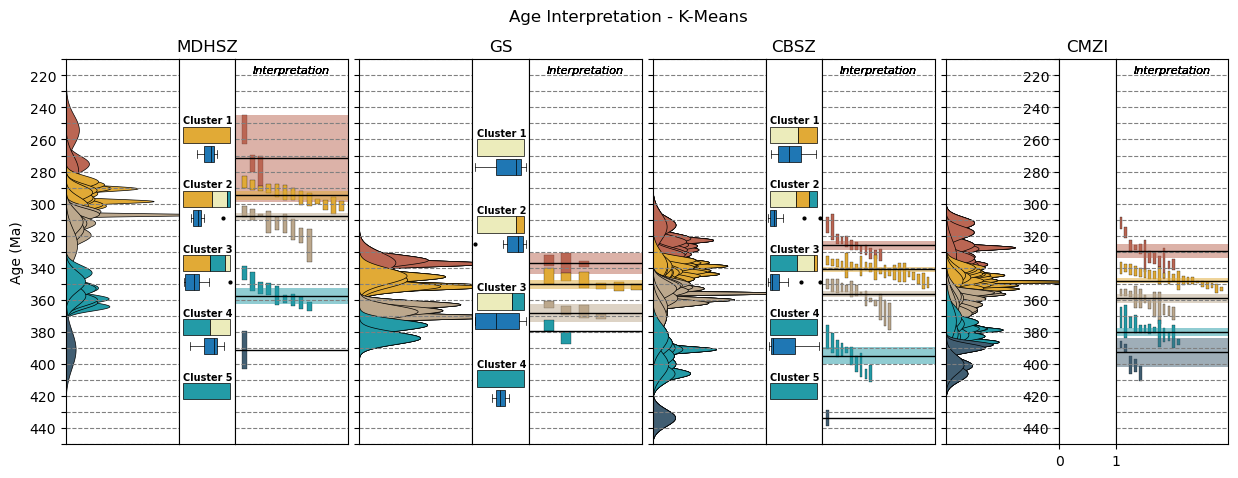

In [98]:


zone_clusters = {'MDHSZ': 5, 
                 'GS': 4, 
                 'CBSZ': 5, 
                 'CMZI': 5}


k_colors = ['#BB6653', '#E1AA36', '#BCA88D', '#239BA7', '#415E72', '#3E3F29']

k_colors_map = {idx:v for idx, v in enumerate(k_colors)}

texture_colors = {'core': '#239BA7', 
                  'overgrowth': '#ECECBB', 
                  'rim': '#E1AA36'}

gap = 0.3
bar_width = 0.4


##### Setup Figure...
fig = plt.figure(figsize=(15, 5))
gs = GridSpec(nrows=1, ncols=15, figure=fig, width_ratios=[1.0, 0.5, 1.0, 
                                                           0.1, 
                                                           1.0, 0.5, 1.0, 
                                                           0.1, 
                                                           1.0, 0.5, 1.0, 
                                                           0.1, 
                                                           1.0, 0.5, 1.0], wspace=0)

# define axes - MDHSZ panel, spacer, GS panel, spacer, CBSZ panel, spacer, CMZI paneel
axA_1 = fig.add_subplot(gs[0, 0])
axA_2 = fig.add_subplot(gs[0, 1], sharey=axA_1)
axA_3 = fig.add_subplot(gs[0, 2], sharey=axA_1)
ax_sp1 = fig.add_subplot(gs[0, 3])                 # spacer
axB_1 = fig.add_subplot(gs[0, 4], sharey=axA_1)
axB_2 = fig.add_subplot(gs[0, 5], sharey=axA_1)
axB_3 = fig.add_subplot(gs[0, 6], sharey=axA_1)
ax_sp2 = fig.add_subplot(gs[0, 7])                 # spacer
axC_1 = fig.add_subplot(gs[0, 8], sharey=axA_1)
axC_2 = fig.add_subplot(gs[0, 9], sharey=axA_1)
axC_3 = fig.add_subplot(gs[0, 10], sharey=axA_1)
ax_sp3 = fig.add_subplot(gs[0, 11])                 # spacer
axD_1 = fig.add_subplot(gs[0, 12], sharey=axA_1)
axD_2 = fig.add_subplot(gs[0, 13], sharey=axA_1)
axD_3 = fig.add_subplot(gs[0, 14], sharey=axA_1)

# hide spacer axes
ax_sp1.axis("off")
ax_sp2.axis("off")
ax_sp3.axis("off")


##### Plot zone panels...
panel1_max = [0.0, 0.0, 0.0, 0.0]
panel3_max = [0.0, 0.0, 0.0, 0.0]

for idx, zone in enumerate(zone_clusters.keys()):

    df_subset = df.loc[df['zone']==zone].copy()
    df_kmeans = kmeans_processing(df_subset, zone_clusters[zone])

    num_clusters = len(df_kmeans['labels'].unique())

    for k, cluster in enumerate(df_kmeans['labels'].unique(), start=1):

        df_kmeans_subset = df_kmeans.loc[df_kmeans['labels'] == cluster].copy()

        if idx==0:
            sample_max = plot_samples_panel(df_kmeans_subset, axA_1, 'labels', k_colors_map, label_bool=True, timeline=[210, 450], ylabel='Age (Ma)', kde=False)

            plot_ageinterp_panel(df_kmeans_subset, axA_3, cluster, k_colors, bar_width, gap)

            texture_counts = df_kmeans_subset['texture'].value_counts().to_dict()
            spacing = (450-210) / (num_clusters + 1)
            center = 210 + (k * spacing)
            horizontal_stack(axA_2, f"Cluster {k}", center, texture_counts, texture_colors, df_kmeans_subset['Y2O3'].to_numpy())
            axA_2.set_title(zone, loc='center')

            
        elif idx==1:
            sample_max = plot_samples_panel(df_kmeans, axB_1, 'labels', k_colors_map, label_bool=False, timeline=[210, 450], ylabel='Age (Ma)', kde=False)

            plot_ageinterp_panel(df_kmeans_subset, axB_3, cluster, k_colors, bar_width, gap)

            texture_counts = df_kmeans_subset['texture'].value_counts().to_dict()
            spacing = (450-210) / (num_clusters + 1)
            center = 210 + (k * spacing)
            horizontal_stack(axB_2, f"Cluster {k}", center, texture_counts, texture_colors, df_kmeans_subset['Y2O3'].to_numpy())
            axB_2.set_title(zone, loc='center')
        

        elif idx==2:
            sample_max = plot_samples_panel(df_kmeans, axC_1, 'labels', k_colors_map, label_bool=False, timeline=[210, 450], ylabel='Age (Ma)', kde=False)

            plot_ageinterp_panel(df_kmeans_subset, axC_3, cluster, k_colors, bar_width, gap)
            

            texture_counts = df_kmeans_subset['texture'].value_counts().to_dict()
            spacing = (450-210) / (num_clusters + 1)
            center = 210 + (k * spacing)
            horizontal_stack(axC_2, f"Cluster {k}", center, texture_counts, texture_colors, df_kmeans_subset['Y2O3'].to_numpy())
            axC_2.set_title(zone, loc='center')
        
        
        elif idx==3:
            sample_max = plot_samples_panel(df_kmeans, axD_1, 'labels', k_colors_map, label_bool=False, timeline=[210, 450], ylabel='Age (Ma)', kde=False)

            plot_ageinterp_panel(df_kmeans_subset, axD_3, cluster, k_colors, bar_width, gap)
            

            texture_counts = df_kmeans_subset['texture'].value_counts().to_dict()
            spacing = (450-210) / (num_clusters + 1)
            center = 210 + (k * spacing)
            # horizontal_stack(axD_2, f"Cluster {k}", center, texture_counts, texture_colors, df_kmeans_subset['Y2O3'].to_numpy())
            axD_2.set_title(zone, loc='center')


        panel1_max[idx] = max(panel1_max[idx], sample_max)
    panel3_max[idx] = df_kmeans.value_counts('labels').max()


axA_1.invert_yaxis()

axA_1.set_xlim(0, panel1_max[0] * (bar_width + gap + 0.05))
axA_3.set_xlim(0, panel3_max[0] * (bar_width + gap + 0.05))

axB_1.set_xlim(0, panel1_max[1] * (bar_width + gap + 0.05))
axB_3.set_xlim(0, panel3_max[1] * (bar_width + gap + 0.05))

axC_1.set_xlim(0, panel1_max[2] * (bar_width + gap + 0.05))
axC_3.set_xlim(0, panel3_max[2] * (bar_width + gap + 0.05))

axD_1.set_xlim(0, panel1_max[3] * (bar_width + gap + 0.05))
axD_3.set_xlim(0, panel3_max[3] * (bar_width + gap + 0.05))




plt.suptitle('Age Interpretation - K-Means')
plt.show()